In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, RocCurveDisplay)

In [2]:
df_data = pd.read_csv('../data/raw/student_dropout_risk_2026.csv')
df_data

,person_id,age,gender,nationality,first_generation,disability_status,family_income_level,scholarship_holder,tuition_up_to_date,part_time_job,...,library_visits_per_month,lms_logins_per_week,extracurricular_activities,missed_deadlines,stress_level,mental_health_support,satisfaction_score,commute_time_mins,sleep_hours,dropout
0,1,23,Male,Brazil,0,0,Low,1,0,1,...,4,16.3,0,3,8,0,6,37,5.7,0
1,2,18,Other,USA,1,1,High,1,1,0,...,3,8.4,1,1,7,0,6,15,5.4,1
2,3,24,Other,USA,0,0,High,0,1,1,...,3,11.3,1,0,2,0,3,4,4.3,0
3,4,25,Female,USA,0,1,Middle,1,1,0,...,2,13.2,1,1,5,0,7,10,6.7,0
4,5,15,Female,Canada,0,0,Low,1,1,0,...,4,7.4,1,0,7,0,10,24,5.8,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,99996,25,Female,USA,0,0,Middle,1,1,1,...,10,6.2,0,0,4,0,6,11,5.9,0
99996,99997,24,Female,India,0,1,Middle,0,1,1,...,0,8.7,1,3,7,1,5,21,5.5,1
99997,99998,27,Female,USA,0,0,Middle,1,1,1,...,8,7.5,0,2,2,0,6,29,5.8,0
99998,99999,21,Male,UK,0,0,High,0,1,0,...,6,13.6,1,2,4,1,10,43,6.2,0


In [3]:
df_data.columns

Index(['person_id', 'age', 'gender', 'nationality', 'first_generation',
       'disability_status', 'family_income_level', 'scholarship_holder',
       'tuition_up_to_date', 'part_time_job', 'weekly_work_hours',
       'course_type', 'study_mode', 'semester', 'international_student',
       'admission_grade', 'previous_qualification_grade', 'units_enrolled',
       'units_passed', 'units_failed', 'gpa_semester_1', 'gpa_semester_2',
       'attendance_rate', 'assignments_submitted_rate',
       'library_visits_per_month', 'lms_logins_per_week',
       'extracurricular_activities', 'missed_deadlines', 'stress_level',
       'mental_health_support', 'satisfaction_score', 'commute_time_mins',
       'sleep_hours', 'dropout'],
      dtype='str')

## Logistic Regression
Predicting `dropout` from student features.



In [7]:
target = 'dropout'
print(df_data[target].value_counts(normalize=True))

X = df_data.drop(columns=[target, 'person_id', 'nationality'])
y = df_data[target]
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

dropout
0    0.67996
1    0.32004
Name: proportion, dtype: float64


/var/folders/fd/qz2fqfqx151f3nkfb0lkfhc00000gn/T/ipykernel_51945/196928627.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()


In [8]:
preprocess = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('oh', OneHotEncoder(handle_unknown='ignore'))]), cat_cols),
])

log_reg = Pipeline([
    ('prep', preprocess),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced')),
])
log_reg.fit(X_train, y_train)

y_pred = log_reg.predict(X_test)
y_prob = log_reg.predict_proba(X_test)[:, 1]
print(classification_report(y_test, y_pred))
print('ROC AUC:', roc_auc_score(y_test, y_prob))

              precision    recall  f1-score   support

           0       0.91      0.82      0.86     13599
           1       0.68      0.82      0.75      6401

    accuracy                           0.82     20000
   macro avg       0.79      0.82      0.80     20000
weighted avg       0.84      0.82      0.82     20000

ROC AUC: 0.9031761378100174


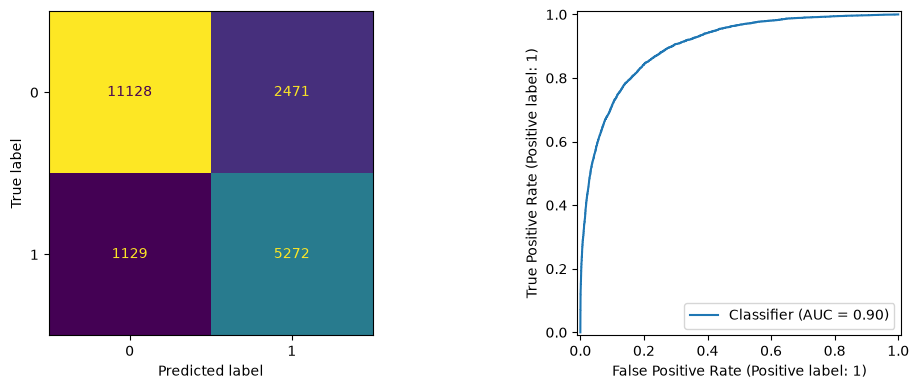

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot(ax=ax[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, y_prob, ax=ax[1])
plt.tight_layout(); plt.show()

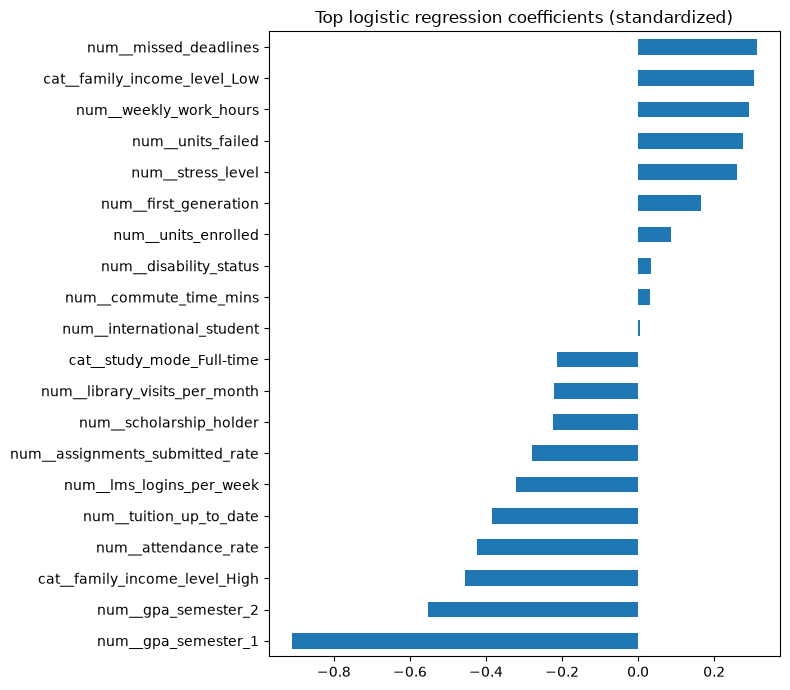

In [10]:
import pandas as pd
names = log_reg.named_steps['prep'].get_feature_names_out()
coefs = pd.Series(log_reg.named_steps['clf'].coef_[0], index=names).sort_values()
top = pd.concat([coefs.head(10), coefs.tail(10)])
top.plot.barh(figsize=(8, 7), title='Top logistic regression coefficients (standardized)')
plt.tight_layout(); plt.show()

In [11]:
coef_df = pd.DataFrame({
    'feature': names,
    'coefficient': log_reg.named_steps['clf'].coef_[0],
})
coef_df['odds_ratio'] = np.exp(coef_df['coefficient'])
coef_df = coef_df.reindex(coef_df['coefficient'].abs().sort_values(ascending=False).index).reset_index(drop=True)
print('Intercept:', log_reg.named_steps['clf'].intercept_[0])
with pd.option_context('display.max_rows', None):
    display(coef_df)

Intercept: -0.26391924418904195


,feature,coefficient,odds_ratio
0,num__gpa_semester_1,-0.910037,0.402509
1,num__gpa_semester_2,-0.552798,0.575338
2,cat__family_income_level_High,-0.455113,0.634376
3,num__attendance_rate,-0.424721,0.653952
4,num__tuition_up_to_date,-0.383305,0.681605
5,num__lms_logins_per_week,-0.320618,0.725700
6,num__missed_deadlines,0.311918,1.366043
7,cat__family_income_level_Low,0.303705,1.354870
8,num__weekly_work_hours,0.291625,1.338601
9,num__assignments_submitted_rate,-0.279902,0.755858


In [ ]:
"""
I thought it wasn't a good idea to have nationality as one of the predictive features because it shouldn't affect dropout rates.
I compared the results after removing nationality. 
I also did a group metrics analysis, to see whether the model predicts the same for each group. Groups can be nationality, income, etc.
If each item in the group has a similar accuracy, this is a good sign, it means the model is predicting them equaly. 
If they are very different from one another, it means the model is over or under predicting a few groups for some reason. 

In this analysis, accuracies for nationality, gender, and international student are very similar, so the model doesn't bias much in any of these items. 
For family income and first generation, the accuracies are more different.
The model flags 53% of low-income students, against 23% of high-income students. 
Actual dropout rates are 43% and 20%, so the model mostly reflects a real difference in the data. 
It is also less fair to low-income students: their false positive rate is 0.27, against 0.11 for high-income students, so more low-income students are wrongly flagged.
"""
from sklearn.metrics import recall_score, accuracy_score

def group_metrics(col):
    # group labels come from the original data (nationality is no longer a model feature)
    g = df_data.loc[X_test.index, col]
    rows = []
    for name in sorted(g.unique(), key=str):
        m = (g == name).to_numpy()
        yt, yp = y_test[m], y_pred[m]
        neg = (yt == 0).sum()
        rows.append({
            col: name,
            'n': int(m.sum()),
            'actual_dropout_rate': yt.mean(),
            'predicted_dropout_rate': yp.mean(),
            'recall (TPR)': recall_score(yt, yp),
            'false_positive_rate': ((yp == 1) & (yt == 0)).sum() / neg if neg else np.nan,
            'accuracy': accuracy_score(yt, yp),
        })
    return pd.DataFrame(rows).round(3)

for col in ['nationality', 'gender', 'family_income_level', 'first_generation', 'international_student']:
    print(f'\n=== {col} ===')
    display(group_metrics(col))


=== nationality ===


,nationality,n,actual_dropout_rate,predicted_dropout_rate,recall (TPR),false_positive_rate,accuracy
0,Australia,193,0.373,0.404,0.806,0.165,0.824
1,Brazil,1378,0.305,0.372,0.845,0.164,0.839
2,Canada,418,0.328,0.411,0.891,0.178,0.844
3,China,2023,0.333,0.397,0.816,0.188,0.814
4,Egypt,403,0.283,0.390,0.781,0.235,0.769
5,Germany,814,0.310,0.394,0.806,0.210,0.795
6,India,2405,0.316,0.393,0.842,0.185,0.824
7,Indonesia,597,0.348,0.389,0.817,0.159,0.832
8,Mexico,1219,0.318,0.386,0.812,0.187,0.813
9,Nigeria,1156,0.311,0.401,0.838,0.203,0.810



=== gender ===


,gender,n,actual_dropout_rate,predicted_dropout_rate,recall (TPR),false_positive_rate,accuracy
0,Female,10117,0.316,0.386,0.825,0.183,0.820
1,Male,9530,0.324,0.389,0.823,0.181,0.820
2,Other,353,0.323,0.380,0.807,0.176,0.819



=== family_income_level ===


,family_income_level,n,actual_dropout_rate,predicted_dropout_rate,recall (TPR),false_positive_rate,accuracy
0,High,4975,0.198,0.232,0.719,0.111,0.855
1,Low,6932,0.429,0.531,0.873,0.274,0.789
2,Middle,8093,0.302,0.360,0.805,0.167,0.825



=== first_generation ===


,first_generation,n,actual_dropout_rate,predicted_dropout_rate,recall (TPR),false_positive_rate,accuracy
0,0,11617,0.282,0.338,0.795,0.158,0.829
1,1,8383,0.373,0.456,0.854,0.219,0.808



=== international_student ===


,international_student,n,actual_dropout_rate,predicted_dropout_rate,recall (TPR),false_positive_rate,accuracy
0,0,16409,0.318,0.387,0.828,0.182,0.821
1,1,3591,0.331,0.387,0.804,0.180,0.815


,threshold,precision,recall,f1,flagged_share,false_positive_rate
0,0.3,0.568,0.916,0.701,0.516,0.328
1,0.4,0.623,0.879,0.729,0.452,0.251
2,0.5,0.681,0.824,0.745,0.387,0.182
3,0.6,0.739,0.760,0.749,0.329,0.126
4,0.7,0.797,0.675,0.731,0.271,0.081
5,0.8,0.858,0.555,0.674,0.207,0.043


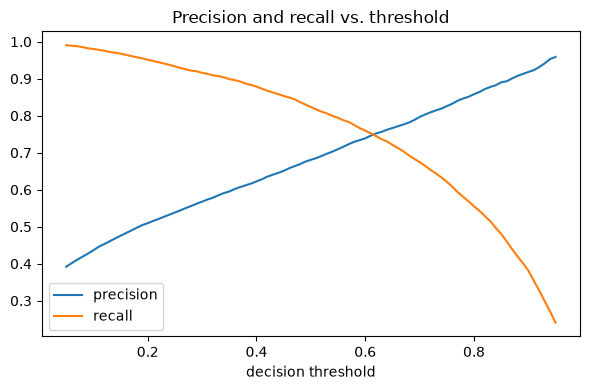

In [ ]:
"""
This analyses the ideal threshold for logistic regression
"""
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
rows = []
for t in thresholds:
    pred_t = (y_prob >= t).astype(int)
    rows.append({
        'threshold': t,
        'precision': precision_score(y_test, pred_t),
        'recall': recall_score(y_test, pred_t),
        'f1': f1_score(y_test, pred_t),
        'flagged_share': pred_t.mean(),
        'false_positive_rate': ((pred_t == 1) & (y_test == 0)).sum() / (y_test == 0).sum(),
    })
threshold_df = pd.DataFrame(rows).round(3)
display(threshold_df)

fig, ax = plt.subplots(figsize=(6, 4))
fine = np.arange(0.05, 0.96, 0.01)
ax.plot(fine, [precision_score(y_test, (y_prob >= t).astype(int)) for t in fine], label='precision')
ax.plot(fine, [recall_score(y_test, (y_prob >= t).astype(int)) for t in fine], label='recall')
ax.set_xlabel('decision threshold'); ax.legend(); ax.set_title('Precision and recall vs. threshold')
plt.tight_layout(); plt.show()